In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

# Generate synthetic data with a linear relationship and random noise
X = np.linspace(0, 10, 100)
y = 3 * X + 5 + np.random.normal(0, 2, 100)

X = X.reshape(-1, 1)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (100, 1)
y shape: (100,)


In [2]:
# Add an intercept column to the design matrix
X_design = np.c_[np.ones(X.shape[0]), X]

# Estimate coefficients using the pseudoinverse
theta = np.linalg.pinv(X_design) @ y

# Generate predictions
y_pred = X_design @ theta

print("Intercept:", round(theta[0], 4))
print("Slope:", round(theta[1], 4))

Intercept: 4.6544
Slope: 3.0276


In [3]:
# Calculate regression evaluation metrics
mse = np.mean((y - y_pred) ** 2)
rmse = np.sqrt(mse)
r2 = 1 - (
    np.sum((y - y_pred) ** 2)
    / np.sum((y - np.mean(y)) ** 2)
)

print("MSE:", round(mse, 4))
print("RMSE:", round(rmse, 4))
print("R²:", round(r2, 4))

MSE: 3.2596
RMSE: 1.8054
R²: 0.9599


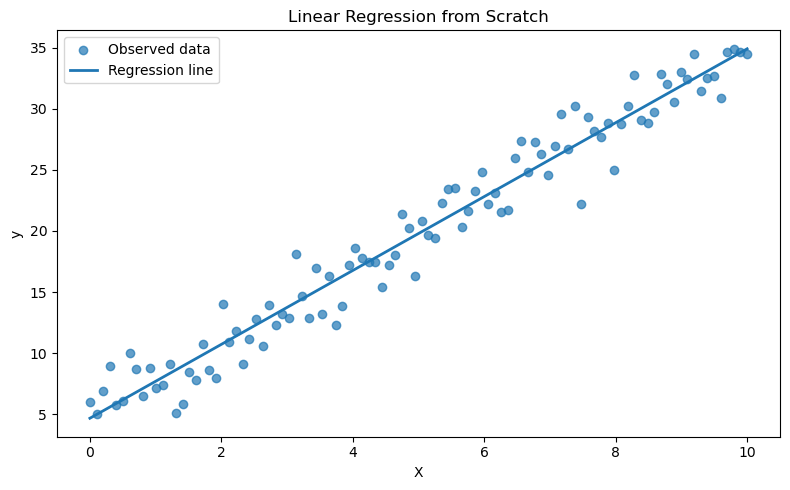

In [4]:
# Visualize the observed data and fitted regression line
plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], y, alpha=0.7, label="Observed data")
plt.plot(X[:, 0], y_pred, linewidth=2, label="Regression line")

plt.xlabel("X")
plt.ylabel("y")
plt.title("Linear Regression from Scratch")
plt.legend()
plt.tight_layout()

# Save the regression plot
plt.savefig(
    "../reports/figures/regression_results.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [5]:
# Initialize parameters for Gradient Descent
theta_gd = np.zeros(2)
learning_rate = 0.01
epochs = 2000
m = len(y)

loss_history = []

# Iteratively update parameters to minimize mean squared error
for epoch in range(epochs):
    predictions = X_design @ theta_gd
    errors = predictions - y

    gradients = (2 / m) * (X_design.T @ errors)
    theta_gd -= learning_rate * gradients

    # Record the loss after updating the parameters
    updated_predictions = X_design @ theta_gd
    loss = np.mean((updated_predictions - y) ** 2)
    loss_history.append(loss)

print("Gradient Descent Intercept:", round(theta_gd[0], 4))
print("Gradient Descent Slope:", round(theta_gd[1], 4))
print("Final MSE:", round(loss_history[-1], 4))

Gradient Descent Intercept: 4.6542
Gradient Descent Slope: 3.0276
Final MSE: 3.2596


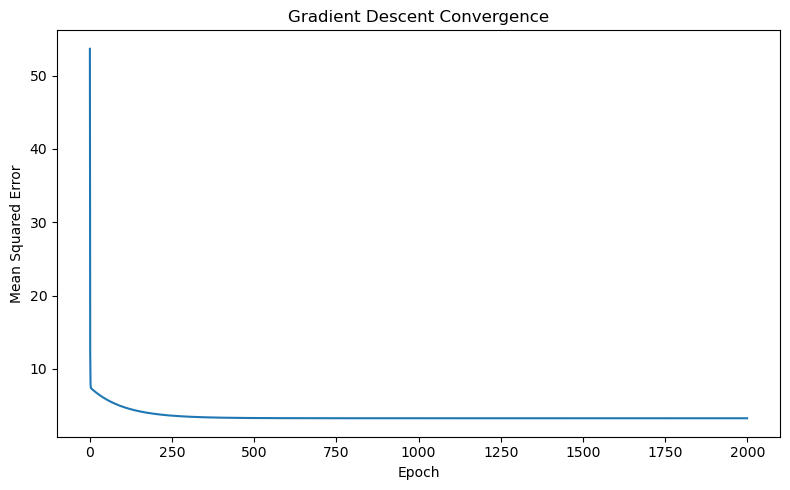

In [6]:
# Visualize how the loss decreases during training
plt.figure(figsize=(8, 5))
plt.plot(loss_history)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Gradient Descent Convergence")
plt.tight_layout()

# Save the convergence plot
plt.savefig(
    "../reports/figures/gradient_descent_convergence.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [7]:
# Compare the closed-form solution with Gradient Descent
comparison = pd.DataFrame({
    "Method": ["Closed-Form Solution", "Gradient Descent"],
    "Intercept": [theta[0], theta_gd[0]],
    "Slope": [theta[1], theta_gd[1]],
    "MSE": [
        np.mean((y - X_design @ theta) ** 2),
        np.mean((y - X_design @ theta_gd) ** 2)
    ]
})

comparison

,Method,Intercept,Slope,MSE
0,Closed-Form Solution,4.654374,3.027587,3.259619
1,Gradient Descent,4.654179,3.027616,3.259619


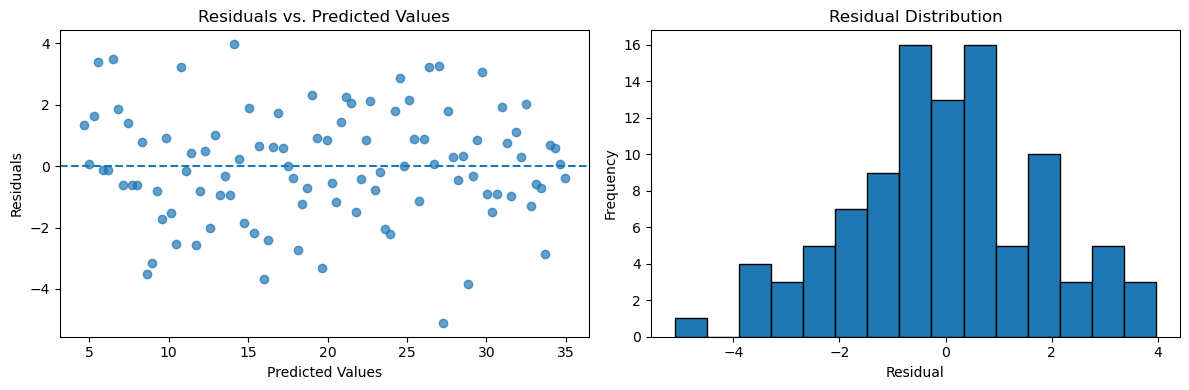

In [8]:
# Calculate residuals using observed and predicted values
residuals = y - y_pred

# Create two plots for residual analysis
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Plot residuals against predicted values
axes[0].scatter(y_pred, residuals, alpha=0.7)
axes[0].axhline(0, linestyle="--")
axes[0].set_xlabel("Predicted Values")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs. Predicted Values")

# Examine the distribution of residuals
axes[1].hist(residuals, bins=15, edgecolor="black")
axes[1].set_xlabel("Residual")
axes[1].set_ylabel("Frequency")
axes[1].set_title("Residual Distribution")

plt.tight_layout()

# Save the residual analysis plots
plt.savefig(
    "../reports/figures/residual_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [9]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Add intercept columns to the design matrices
X_train_design = np.c_[np.ones(X_train.shape[0]), X_train]
X_test_design = np.c_[np.ones(X_test.shape[0]), X_test]

# Train the model using training data only
theta_train = np.linalg.pinv(X_train_design) @ y_train

# Predict values for the unseen test set
y_test_pred = X_test_design @ theta_train

# Evaluate generalization performance
test_mse = np.mean((y_test - y_test_pred) ** 2)
test_rmse = np.sqrt(test_mse)
test_r2 = 1 - (
    np.sum((y_test - y_test_pred) ** 2)
    / np.sum((y_test - np.mean(y_test)) ** 2)
)

print("Test MSE:", round(test_mse, 4))
print("Test RMSE:", round(test_rmse, 4))
print("Test R²:", round(test_r2, 4))

Test MSE: 2.4882
Test RMSE: 1.5774
Test R²: 0.9683


In [10]:
# Compare actual and predicted values on the test set
results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_test_pred,
    "Residual": y_test - y_test_pred
})

results.head(10)

,Actual,Predicted,Residual
0,29.114975,29.993707,-0.878732
1,22.283959,20.829561,1.454398
2,26.934912,26.022577,0.912335
3,17.196675,18.385789,-1.189114
4,15.376289,18.080317,-2.704028
5,17.211904,16.552960,0.658944
6,11.801723,11.359944,0.441779
7,28.803080,29.077292,-0.274212
8,7.103468,7.694286,-0.590818
9,5.993428,4.639570,1.353858


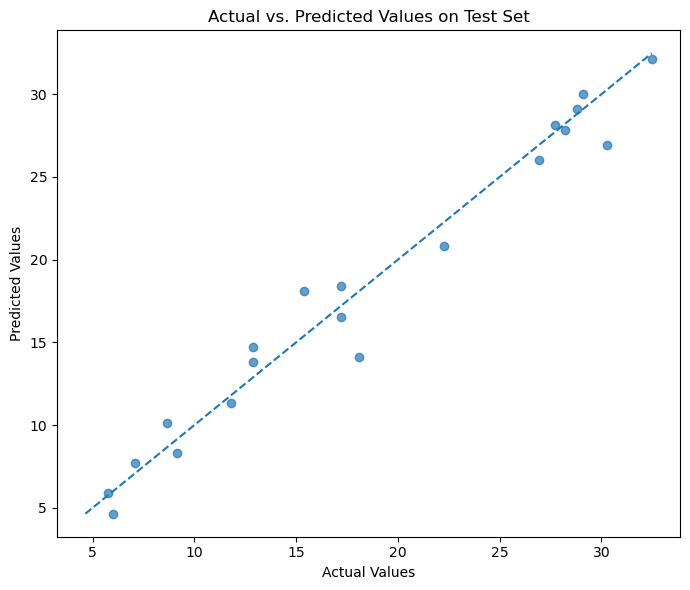

In [11]:
# Compare actual and predicted values visually
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_test_pred, alpha=0.7)

# Add a reference line representing perfect predictions
lower = min(y_test.min(), y_test_pred.min())
upper = max(y_test.max(), y_test_pred.max())
plt.plot([lower, upper], [lower, upper], linestyle="--")

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs. Predicted Values on Test Set")
plt.tight_layout()

# Save the test prediction plot
plt.savefig(
    "../reports/figures/test_predictions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [12]:
import sys
from pathlib import Path

# Add the project root to the Python import path
project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

# Import the reusable regression functions
from src.regression import (
    fit_linear_regression,
    predict,
    evaluate_regression
)

# Fit the model and generate predictions
theta_src = fit_linear_regression(X_train, y_train)
y_pred_src = predict(X_test, theta_src)

# Evaluate the model on the test set
metrics = evaluate_regression(y_test, y_pred_src)

print("Intercept:", round(theta_src[0], 4))
print("Slope:", round(theta_src[1], 4))

for metric, value in metrics.items():
    print(f"{metric}: {value:.4f}")

Intercept: 4.6396
Slope: 3.0242
MSE: 2.4882
RMSE: 1.5774
R2: 0.9683


In [13]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Train the scikit-learn model using the same training data
sklearn_model = LinearRegression()
sklearn_model.fit(X_train, y_train)

# Generate predictions on the test set
y_pred_sklearn = sklearn_model.predict(X_test)

# Compare the custom model with scikit-learn
comparison = pd.DataFrame({
    "Implementation": ["Custom Model", "scikit-learn"],
    "Intercept": [
        theta_src[0],
        sklearn_model.intercept_
    ],
    "Slope": [
        theta_src[1],
        sklearn_model.coef_[0]
    ],
    "Test MSE": [
        metrics["MSE"],
        mean_squared_error(y_test, y_pred_sklearn)
    ],
    "Test R2": [
        metrics["R2"],
        r2_score(y_test, y_pred_sklearn)
    ]
})

comparison.round(4)

,Implementation,Intercept,Slope,Test MSE,Test R2
0,Custom Model,4.6396,3.0242,2.4882,0.9683
1,scikit-learn,4.6396,3.0242,2.4882,0.9683
